# Exploratory analysis of daily VIX closes

This notebook describes the prepared sample before any model is fitted. It answers four questions that the modelling stage depends on:

1. What do VIX closing levels look like, and how are they distributed?
2. How large are day-to-day changes, and how concentrated are the big ones?
3. Is the series stationary in levels, or does it need differencing?
4. How strongly do past values relate to the next one?

**Rule used throughout.** The full series is plotted once for context. Every statistic and diagnostic after that is computed on the **training period only (2015–2021)**, so nothing learned here depends on validation or test observations.

Run `scripts/prepare_data.ps1` first; it creates the input file read below.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.tools.sm_exceptions import InterpolationWarning
from statsmodels.tsa.stattools import acf, adfuller, kpss, pacf
import warnings

# The notebook lives in notebooks/, one level below the project root.
ROOT = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
FIGURES = ROOT / "report" / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)

INK, TEAL, MUTED, GRID = "#172C36", "#087E83", "#52636A", "#DDE3E6"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 160, "savefig.bbox": "tight",
    "font.size": 10, "text.color": INK, "axes.labelcolor": MUTED,
    "axes.edgecolor": GRID, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "axes.titlelocation": "left", "axes.titleweight": "bold", "axes.titlesize": 11,
})

## 1. Load the prepared sample

The file has one row per NYSE regular session. The checks repeat the key guarantees from the data audit, so the notebook fails loudly if it is run on a different file.

In [2]:
vix = pd.read_csv(
    ROOT / "data" / "processed" / "vix_daily_2015_2025.csv",
    parse_dates=["date"], index_col="date",
)["vix_close"]

sessions = pd.read_csv(ROOT / "data" / "calendar" / "xnys_sessions_2015_2025.csv", parse_dates=["date"])["date"]

assert vix.index.equals(pd.DatetimeIndex(sessions)), "Sample dates differ from the frozen session calendar."
assert vix.notna().all() and (vix > 0).all(), "Unexpected missing or non-positive closes."

print(f"{len(vix):,} observations from {vix.index[0].date()} to {vix.index[-1].date()}")

2,766 observations from 2015-01-02 to 2025-12-31


## 2. Chronological split

The split is the provisional one from the report. Later observations are never used to describe or model earlier ones.

In [3]:
SPLITS = {
    "Training": ("2015", "2021"),
    "Validation": ("2022", "2023"),
    "Test": ("2024", "2025"),
}

split_table = pd.DataFrame({
    name: {
        "first date": vix.loc[start:end].index[0].date(),
        "last date": vix.loc[start:end].index[-1].date(),
        "observations": len(vix.loc[start:end]),
    }
    for name, (start, end) in SPLITS.items()
}).T
split_table

,first date,last date,observations
Training,2015-01-02,2021-12-31,1763
Validation,2022-01-03,2023-12-29,501
Test,2024-01-02,2025-12-31,502


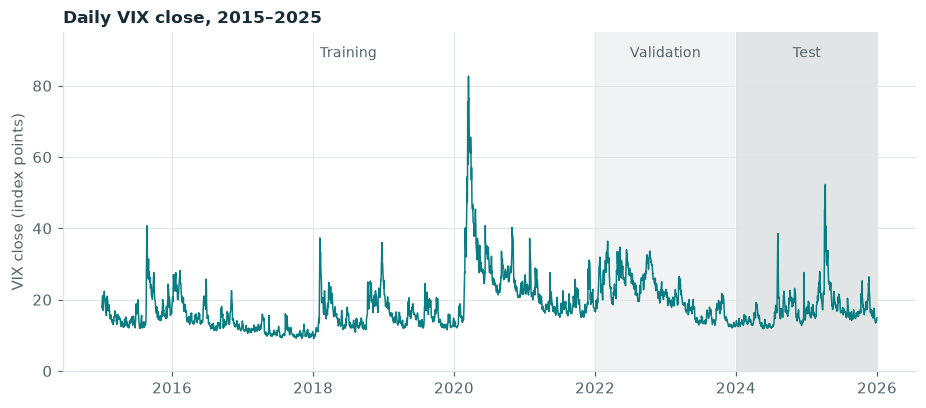

In [4]:
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(vix.index, vix.values, color=TEAL, linewidth=1)

# Shade the two hold-out periods and label all three directly.
for name, (start, end), shade in [("Validation", SPLITS["Validation"], 0.06), ("Test", SPLITS["Test"], 0.12)]:
    ax.axvspan(vix.loc[start:end].index[0], vix.loc[start:end].index[-1], color=INK, alpha=shade, linewidth=0)
for name, (start, end) in SPLITS.items():
    period = vix.loc[start:end].index
    ax.text(period[0] + (period[-1] - period[0]) / 2, 88, name, ha="center", color=MUTED, fontsize=9)

ax.set_ylim(0, 95)
ax.set_ylabel("VIX close (index points)")
ax.set_title("Daily VIX close, 2015–2025")
fig.savefig(FIGURES / "vix_close_2015_2025.png")
plt.show()

The plot is context only. From here on, `train` is the only data used.

In [5]:
train = vix.loc[SPLITS["Training"][0]:SPLITS["Training"][1]]
print(f"Training period: {len(train):,} observations")

Training period: 1,763 observations


## 3. Closing levels in the training period

In [6]:
level_summary = train.describe(percentiles=[0.05, 0.25, 0.5, 0.75, 0.95]).round(2)
level_summary["skewness"] = round(train.skew(), 2)
level_summary["excess kurtosis"] = round(train.kurt(), 2)
level_summary.to_frame("VIX close")

,VIX close
count,1763.00
mean,17.80
std,7.81
min,9.14
5%,10.26
25%,12.86
50%,15.78
75%,20.56
95%,30.52
max,82.69


In [7]:
print(f"Lowest close:  {train.min():.2f} on {train.idxmin().date()}")
print(f"Highest close: {train.max():.2f} on {train.idxmax().date()}")
print(f"Share of days below 15: {(train < 15).mean():.1%}")
print(f"Share of days above 30: {(train > 30).mean():.1%}")
print(f"Skewness of log levels: {np.log(train).skew():.2f}")

Lowest close:  9.14 on 2017-11-03
Highest close: 82.69 on 2020-03-16
Share of days below 15: 44.0%
Share of days above 30: 5.4%
Skewness of log levels: 0.97


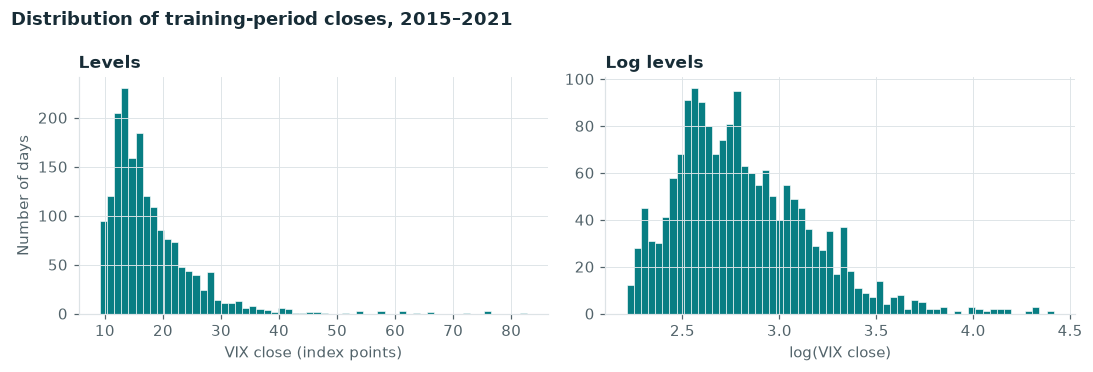

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))

axes[0].hist(train, bins=60, color=TEAL, edgecolor="white", linewidth=0.4)
axes[0].set_title("Levels")
axes[0].set_xlabel("VIX close (index points)")
axes[0].set_ylabel("Number of days")

axes[1].hist(np.log(train), bins=60, color=TEAL, edgecolor="white", linewidth=0.4)
axes[1].set_title("Log levels")
axes[1].set_xlabel("log(VIX close)")

fig.suptitle("Distribution of training-period closes, 2015–2021", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
plt.show()

**Reading.** Most of the time the VIX is low and calm: the median close is 15.78 and 44% of training days close below 15. The distribution has a long right tail (skewness 2.97): only 5.4% of days close above 30, but the maximum is 82.69 on 16 March 2020. The mean (17.80) sits above the median because of that tail.

Taking logs reduces the skewness to 0.97 but does not remove it. The forecast target stays the level in index points, as stated in the report; a log transformation is noted here as an option, not adopted.

The training range (9.14 to 82.69) matters for Random Forest, whose predictions are averages of training targets and therefore cannot fall outside it.

## 4. Day-to-day changes

The change `y_t − y_(t−1)` is exactly the error the naive forecast would make on day *t*. So the size of daily changes is the scale every other model has to beat.

In [9]:
change = train.diff().dropna()

change_summary = pd.Series({
    "observations": len(change),
    "mean": change.mean(),
    "standard deviation": change.std(),
    "median absolute change": change.abs().median(),
    "mean absolute change": change.abs().mean(),
    "root mean squared change": np.sqrt((change ** 2).mean()),
    "skewness": change.skew(),
    "excess kurtosis": change.kurt(),
}).round(3)
change_summary.to_frame("daily change (index points)")

,daily change (index points)
observations,1762.000
mean,-0.000
standard deviation,2.047
median absolute change,0.695
mean absolute change,1.158
root mean squared change,2.046
skewness,2.718
excess kurtosis,32.856


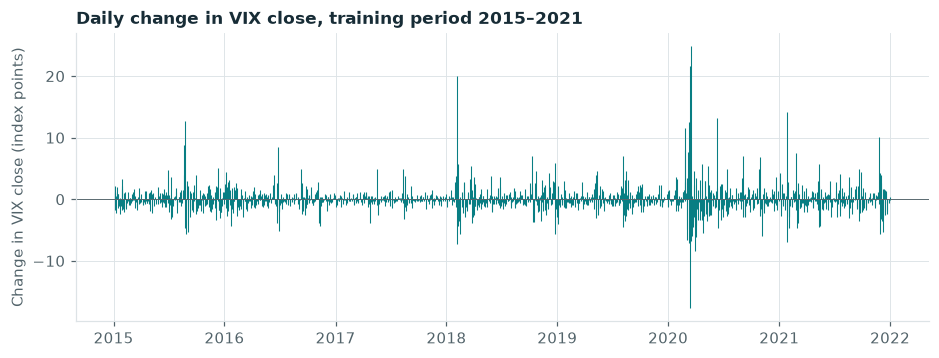

In [10]:
fig, ax = plt.subplots(figsize=(10, 3.4))
ax.vlines(change.index, 0, change.values, color=TEAL, linewidth=0.7)
ax.axhline(0, color=MUTED, linewidth=0.6)
ax.set_ylabel("Change in VIX close (index points)")
ax.set_title("Daily change in VIX close, training period 2015–2021")
fig.savefig(FIGURES / "vix_daily_change_train.png")
plt.show()

In [11]:
largest = change.abs().sort_values(ascending=False).index[:10]
pd.DataFrame({
    "change": change.loc[largest],
    "close that day": train.loc[largest],
}).round(2)

,change,close that day
date,,
2020-03-16,24.86,82.69
2020-03-12,21.57,75.47
2018-02-05,20.01,37.32
2020-03-13,-17.64,57.83
2021-01-27,14.19,37.21
2020-06-11,13.22,40.79
2015-08-24,12.71,40.74
2020-03-09,12.52,54.46
2020-02-27,11.60,39.16


In [12]:
print(f"Days with an absolute change below 1 point: {(change.abs() < 1).mean():.1%}")
print(f"Days with an absolute change above 5 points: {(change.abs() > 5).sum()} ({(change.abs() > 5).mean():.1%})")

# How much of the total squared change comes from the largest days?
squared = (change ** 2).sort_values(ascending=False)
for share in (0.01, 0.05, 0.10):
    days = int(np.ceil(len(squared) * share))
    print(f"Largest {share:.0%} of days ({days:>3}): {squared.iloc[:days].sum() / squared.sum():.0%} of total squared change")

Days with an absolute change below 1 point: 62.8%
Days with an absolute change above 5 points: 44 (2.5%)
Largest 1% of days ( 18): 44% of total squared change
Largest 5% of days ( 89): 68% of total squared change
Largest 10% of days (177): 80% of total squared change


**Reading.** On a typical day the VIX barely moves: the median absolute change is 0.70 points and 63% of days move by less than 1 point. The average change is essentially zero, so there is no drift to exploit.

Large moves are rare but dominate squared error. The 18 largest days (1% of the sample) account for 44% of the total squared change, and the largest 5% account for 68%. Nine of the ten largest moves are increases, and five of the ten fall between late February and mid-March 2020. The changes are right-skewed (2.72) with very heavy tails (excess kurtosis 32.9).

Two consequences for the evaluation:

- The training-period mean absolute change (1.16) and root mean squared change (2.05) are what a naive forecast would have scored on these dates. They describe the scale of the problem; they are **not** test results.
- RMSE will be driven by a handful of days, while MAE reflects ordinary days. The two metrics can rank models differently, which is why both are reported and why error concentration is a stated secondary question.

## 5. Stationarity

ARIMA needs a decision on the differencing order *d*. Two tests with opposite null hypotheses are used together:

- **ADF**: the null is a unit root (non-stationary). A small p-value is evidence *against* a unit root.
- **KPSS**: the null is stationarity around a constant. A small p-value is evidence *against* stationarity.

Both include a constant and no trend. statsmodels reports KPSS p-values only between 0.01 and 0.10, so values at those limits mean "at most 0.01" or "at least 0.10".

In [13]:
def stationarity_tests(series):
    adf = adfuller(series, regression="c", autolag="AIC", result_object=True)
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", InterpolationWarning)  # p-value outside the tabulated range
        kp = kpss(series, regression="c", nlags="auto", result_object=True)
    return {
        "ADF statistic": adf.statistic, "ADF p-value": adf.pvalue, "ADF lags": adf.lags,
        "KPSS statistic": kp.statistic, "KPSS p-value": kp.pvalue, "KPSS lags": kp.lags,
    }

pd.DataFrame({
    "level": stationarity_tests(train),
    "first difference": stationarity_tests(change),
}).T.round(4)

,ADF statistic,ADF p-value,ADF lags,KPSS statistic,KPSS p-value,KPSS lags
level,-4.5296,0.0002,9.0,1.4486,0.01,26.0
first difference,-14.6531,0.0000,8.0,0.0128,0.10,10.0


**Reading.** For the level, the two tests disagree. ADF rejects a unit root (statistic −4.53, p < 0.001), which fits a series that keeps returning towards a typical range. KPSS also rejects stationarity (statistic 1.45 against a 1% critical value of 0.74), which fits a series whose average level differs between calm and turbulent stretches. This combination is common for a very persistent, mean-reverting series and does not settle *d* on its own.

The first difference is clearly stationary under both tests (ADF −14.65; KPSS 0.01).

**Decision.** Neither `d = 0` nor `d = 1` is ruled out by training-period diagnostics. Both stay in the ARIMA candidate set and validation-period forecast accuracy chooses between them.

## 6. Autocorrelation

The dashed lines are ±1.96/√n, the approximate 95% band for a series with no autocorrelation.

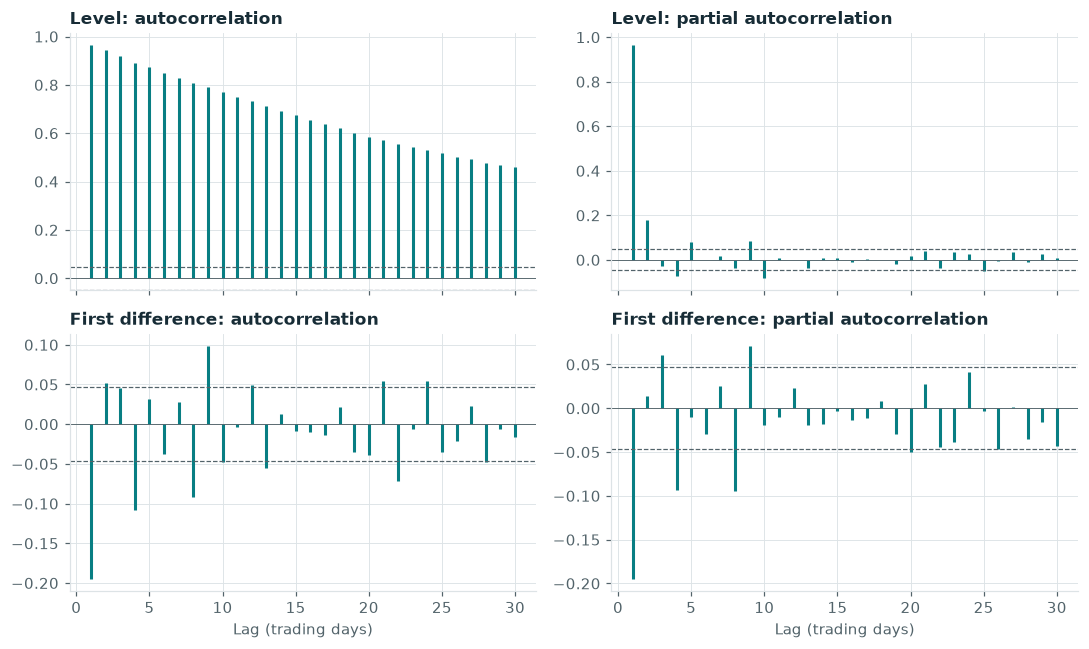

In [14]:
def correlogram(values, ax, title, n_obs):
    lags = np.arange(1, len(values) + 1)
    ax.vlines(lags, 0, values, color=TEAL, linewidth=2)
    band = 1.96 / np.sqrt(n_obs)
    ax.axhline(band, color=MUTED, linewidth=0.8, linestyle="--")
    ax.axhline(-band, color=MUTED, linewidth=0.8, linestyle="--")
    ax.axhline(0, color=MUTED, linewidth=0.6)
    ax.set_title(title)
    ax.set_xlabel("Lag (trading days)")

MAX_LAG = 30
fig, axes = plt.subplots(2, 2, figsize=(10, 6), sharex=True)

correlogram(acf(train, nlags=MAX_LAG)[1:], axes[0, 0], "Level: autocorrelation", len(train))
correlogram(pacf(train, nlags=MAX_LAG, method="ywm")[1:], axes[0, 1], "Level: partial autocorrelation", len(train))
correlogram(acf(change, nlags=MAX_LAG)[1:], axes[1, 0], "First difference: autocorrelation", len(change))
correlogram(pacf(change, nlags=MAX_LAG, method="ywm")[1:], axes[1, 1], "First difference: partial autocorrelation", len(change))

for ax in axes[0]:
    ax.set_xlabel("")
fig.tight_layout()
fig.savefig(FIGURES / "vix_acf_pacf_train.png")
plt.show()

In [15]:
pd.DataFrame({
    "level": acf(train, nlags=5)[1:],
    "first difference": acf(change, nlags=5)[1:],
    "absolute first difference": acf(change.abs(), nlags=5)[1:],
}, index=pd.RangeIndex(1, 6, name="lag")).round(3)

,level,first difference,absolute first difference
lag,,,
1,0.966,-0.195,0.464
2,0.945,0.052,0.398
3,0.920,0.045,0.337
4,0.893,-0.108,0.283
5,0.872,0.032,0.288


In [16]:
acorr_ljungbox(change, lags=[5, 10, 20]).round(4)

,lb_stat,lb_pvalue
5,97.8953,0.0
10,138.1021,0.0
20,154.4554,0.0


**Reading.**

- **Level.** Autocorrelation is 0.97 at lag 1 and decays slowly (0.77 at lag 10, 0.46 at lag 30). The partial autocorrelation is large at lag 1, smaller at lag 2 (0.18) and below 0.1 in absolute value afterwards. Today's close carries most of the usable information, which is why the naive forecast is a demanding benchmark.
- **First difference.** The lag-1 autocorrelation is −0.20: a rise tends to be partly reversed the next day. Later lags are much smaller. The Ljung–Box test rejects "no autocorrelation" at 5, 10 and 20 lags, so the changes are not white noise and there is some linear structure for ARIMA to use.
- **Absolute first difference.** Autocorrelation is 0.46 at lag 1 and fades slowly: large moves cluster in time. The size of the next move is more predictable than its direction.

**Caution.** The band and the Ljung–Box p-values assume independent, constant-variance observations. With heavy tails and clustered volatility they overstate significance, so small autocorrelations at higher lags should not be over-interpreted.

## 7. What this means for the modelling stage

| Finding (training period) | Consequence |
|---|---|
| Lag-1 autocorrelation of 0.97; typical daily change below 1 point | The naive forecast is a strong benchmark; improvements, if any, are likely to be small. |
| ADF and KPSS disagree on the level; the difference is stationary | Keep both `d = 0` and `d = 1` as ARIMA candidates; choose on validation accuracy. |
| Partial autocorrelation concentrated in lags 1–2; lag-1 reversal in changes | A small ARIMA grid with low orders of `p` and `q` is sufficient. |
| 1% of days produce 44% of squared change | Report MAE and RMSE together and show how errors are distributed over time. |
| Large moves cluster; levels are bounded by the training range for tree models | Recent-volatility features are worth testing for Random Forest; its inability to extrapolate is a known limitation. |

Nothing here is a forecast result. Model orders, features, hyperparameters and the refitting schedule are still to be fixed before the test period is touched.